# Praktikum Machine Learning — Bab 1: Konsep Dasar Machine Learning

**Nama:** Mohammad Ikhsan Al Farobbi  
**NPM:** 202343500149  
**Kelas:** R7B  
**Mata Kuliah:** Machine Learning  

## Tujuan Praktikum
Mengenal alur dasar Machine Learning menggunakan Python: menyiapkan library, memuat dan mengeksplorasi dataset, membagi data menjadi data latih dan data uji, melatih model K-Nearest Neighbors (KNN), mengevaluasi hasil prediksi, serta membaca pola pada visualisasi data.

**Dataset:** Iris, dataset bunga dengan tiga kelas spesies.  
**Catatan:** Jalankan setiap sel kode secara berurutan dari atas ke bawah di Google Colab.

## Praktikum 1.1 — Persiapan Library

Library yang digunakan:
- `pandas` dan `numpy` untuk membantu pengolahan data.
- `matplotlib` untuk membuat visualisasi.
- `scikit-learn` untuk dataset Iris, pembagian data, model KNN, dan evaluasi.

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

print("Library berhasil dimuat.")

Library berhasil dimuat.


## Praktikum 1.2 — Memuat Dataset Iris

Dataset Iris tersedia langsung di scikit-learn. Kolom `target` berisi kode kelas, sedangkan `target_name` akan menunjukkan nama spesiesnya.

In [12]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df["target_name"] = df["target"].map(dict(enumerate(iris.target_names)))

print("Ukuran dataset (baris, kolom):", df.shape)
display(df.head())

Ukuran dataset (baris, kolom): (150, 6)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,target_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


**Analisis awal:** `shape` menunjukkan banyaknya baris dan kolom. Lima baris pertama dipakai untuk melihat contoh nilai fitur dan label kelas sebelum model dibuat.

## Praktikum 1.3 — Eksplorasi Awal dan Menentukan X serta y

Fitur (`X`) adalah informasi yang dipakai model untuk membuat prediksi. Target (`y`) adalah kelas yang ingin diprediksi.

In [13]:
print("Informasi dataset:")
df.info()

print("\nJumlah data per kelas:")
print(df["target_name"].value_counts())

X = df[iris.feature_names]
y = df["target"]

print("\nUkuran fitur X:", X.shape)
print("Jumlah target y:", y.shape[0])

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   target_name        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB

Jumlah data per kelas:
target_name
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Ukuran fitur X: (150, 4)
Jumlah target y: 150


**Analisis hasil:** jumlah data pada setiap kelas dapat diperiksa untuk mengetahui apakah dataset memiliki jumlah contoh yang seimbang. Pada latihan ini, `X` berisi empat fitur pengukuran bunga, sedangkan `y` berisi label spesies.

## Praktikum 1.4 — Membagi Data dan Melatih Model KNN

Data dipisahkan menjadi 80% data latih dan 20% data uji. `random_state=42` membuat pembagian dapat diulang, sedangkan `stratify=y` menjaga proporsi kelas agar tetap terwakili pada kedua bagian.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = KNeighborsClassifier(n_neighbors=3)
model.fit(X_train, y_train)

print("Jumlah data latih:", X_train.shape[0])
print("Jumlah data uji:", X_test.shape[0])
print("Model KNN berhasil dilatih.")

Jumlah data latih: 120
Jumlah data uji: 30
Model KNN berhasil dilatih.


**Analisis hasil:** model belajar dari data latih. Data uji disimpan untuk memeriksa performa pada contoh yang tidak dipakai saat proses pelatihan.

## Praktikum 1.5 — Evaluasi Model

Akurasi menunjukkan perbandingan jumlah prediksi yang benar terhadap seluruh prediksi pada data uji.

In [15]:
y_pred = model.predict(X_test)
akurasi = accuracy_score(y_test, y_pred)

print(f"Akurasi model pada data uji: {akurasi:.2%}")
print("Jumlah prediksi benar:", int((y_pred == y_test).sum()), "dari", len(y_test))

Akurasi model pada data uji: 100.00%
Jumlah prediksi benar: 30 dari 30


**Interpretasi:** akurasi yang tampil adalah hasil pengujian pada pembagian data ini. Nilai tersebut bukan jaminan bahwa model akan selalu memperoleh hasil yang sama pada setiap dataset atau pembagian data.

## Visualisasi — Sebaran Data Berdasarkan Fitur Petal

Grafik berikut membandingkan panjang dan lebar petal (mahkota bunga) untuk ketiga spesies.

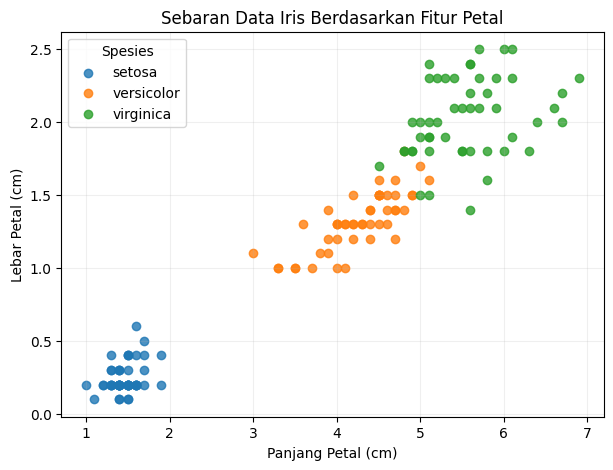

In [16]:
plt.figure(figsize=(7, 5))

for target_value, target_name in enumerate(iris.target_names):
    subset = df[df["target"] == target_value]
    plt.scatter(
        subset["petal length (cm)"],
        subset["petal width (cm)"],
        label=target_name,
        alpha=0.8
    )

plt.xlabel("Panjang Petal (cm)")
plt.ylabel("Lebar Petal (cm)")
plt.title("Sebaran Data Iris Berdasarkan Fitur Petal")
plt.legend(title="Spesies")
plt.grid(alpha=0.2)
plt.show()

### Analisis Visualisasi

Dari grafik, perhatikan apakah titik-titik dari tiap spesies membentuk kelompok yang terpisah atau saling berdekatan. Jika kelompok cukup terpisah, fitur panjang dan lebar petal berpotensi membantu membedakan spesies. Jika ada titik yang berdekatan antarkelas, model dapat lebih sulit membedakannya hanya berdasarkan fitur tersebut.

Tuliskan pengamatan berdasarkan grafik yang benar-benar muncul setelah kode dijalankan.

## Percobaan Tambahan — Pengaruh Jumlah Tetangga KNN

Percobaan ini membandingkan beberapa nilai `n_neighbors` untuk melihat apakah pilihan jumlah tetangga mengubah akurasi pada pembagian data yang sama. Ini merupakan eksplorasi sederhana, bukan pengganti evaluasi yang lebih lengkap.

,Jumlah tetangga (k),Akurasi
0,1,0.966667
1,3,1.000000
2,5,1.000000
3,7,0.966667
4,11,0.966667


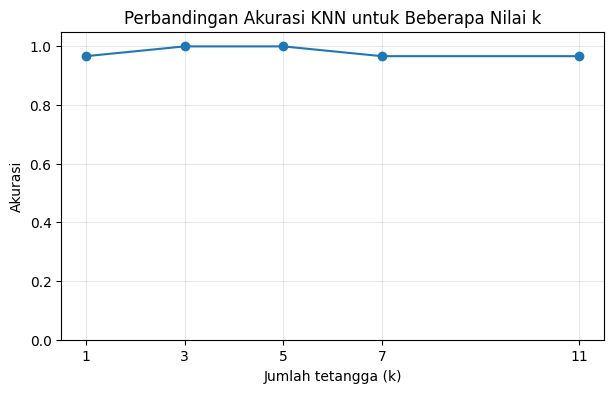

In [17]:
hasil_k = []

for k in [1, 3, 5, 7, 11]:
    model_k = KNeighborsClassifier(n_neighbors=k)
    model_k.fit(X_train, y_train)
    pred_k = model_k.predict(X_test)
    hasil_k.append({
        "Jumlah tetangga (k)": k,
        "Akurasi": accuracy_score(y_test, pred_k)
    })

hasil_k_df = pd.DataFrame(hasil_k)
display(hasil_k_df)

plt.figure(figsize=(7, 4))
plt.plot(hasil_k_df["Jumlah tetangga (k)"], hasil_k_df["Akurasi"], marker="o")
plt.xlabel("Jumlah tetangga (k)")
plt.ylabel("Akurasi")
plt.title("Perbandingan Akurasi KNN untuk Beberapa Nilai k")
plt.xticks(hasil_k_df["Jumlah tetangga (k)"])
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.show()

### Analisis Percobaan Tambahan

Bandingkan nilai akurasi pada tabel dan grafik. Nilai `k` yang lebih kecil memakai tetangga yang lebih sedikit, sedangkan nilai yang lebih besar mempertimbangkan lebih banyak tetangga. Tidak ada nilai `k` yang selalu paling baik untuk semua dataset; hasil percobaan ini berlaku untuk pembagian data yang digunakan di notebook ini.

## Kesimpulan Bab 1

Pada praktikum ini, dataset Iris dimuat dan diperiksa, fitur dan target dipisahkan, data dibagi menjadi data latih dan data uji, lalu model KNN dilatih dan dievaluasi menggunakan akurasi. Visualisasi membantu melihat hubungan antara fitur petal dan kelas spesies. Percobaan tambahan menunjukkan bahwa nilai `k` dapat memengaruhi hasil model.
